Learned Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
Goal Reached: True


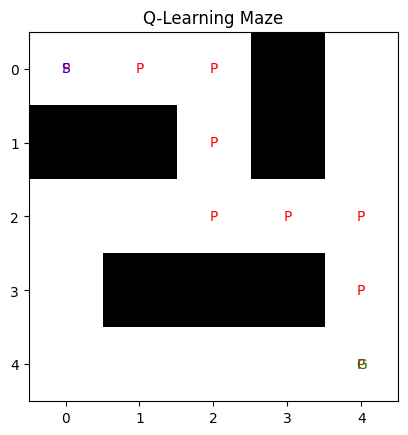

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt

# Create Maze (0 = Path, 1 = Wall)
maze = np.array([
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

start = (0, 0)
goal = (4, 4)

# Actions: Up, Down, Left, Right
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Initialize Q-table
q = np.zeros((25, 4))

# Q-Learning
for episode in range(1000):
    position = start

    for step in range(100):
        state = position[0] * 5 + position[1]

        action = random.randint(0, 3) if random.random() < 0.2 else np.argmax(q[state])

        r = position[0] + actions[action][0]
        c = position[1] + actions[action][1]

        if 0 <= r < 5 and 0 <= c < 5 and maze[r, c] == 0:
            new_position = (r, c)
        else:
            new_position = position

        reward = 100 if new_position == goal else -1

        next_state = new_position[0] * 5 + new_position[1]

        q[state, action] += 0.8 * (
            reward + 0.9 * np.max(q[next_state]) - q[state, action]
        )

        position = new_position

        if position == goal:
            break

# Display learned path
position = start
path = [position]

for step in range(30):
    state = position[0] * 5 + position[1]
    action = np.argmax(q[state])

    r = position[0] + actions[action][0]
    c = position[1] + actions[action][1]

    if 0 <= r < 5 and 0 <= c < 5 and maze[r, c] == 0:
        position = (r, c)
    else:
        break

    path.append(position)

    if position == goal:
        break

print("Learned Path:", path)
print("Goal Reached:", position == goal)

# Plot Maze
plt.imshow(maze, cmap='gray_r')

for r, c in path:
    plt.text(c, r, 'P', ha='center', va='center', color='red')

plt.text(0, 0, 'S', ha='center', va='center', color='blue')
plt.text(4, 4, 'G', ha='center', va='center', color='green')

plt.title("Q-Learning Maze")
plt.show()
